In [ ]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver     # for demo using InMemorySaver (RAM)

In [2]:
# load env
load_dotenv()

True

In [3]:
# define google gemini model
llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

In [4]:
# define state
class JokeState(TypedDict):

    topic: str
    joke: str
    explanation: str

In [5]:
# define generate_joke function
def generate_joke(state: JokeState):

    prompt = f'generate a joke on the topic {state["topic"]}'
    response = llm.invoke(prompt)

    return { 'joke': response }

In [6]:
# define generate_explanation function
def generate_explanation(state: JokeState):

    prompt = f'write an explanation for the joke - {state["joke"]}'
    response = llm.invoke(prompt)

    return { 'explanation': response }

In [7]:
# define graph
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explanation', generate_explanation)

# add edges
graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explanation')
graph.add_edge('generate_explanation', END)

# add persistence using checkPointer
checkpointer = InMemorySaver()

# compile graph
workflow = graph.compile(checkpointer=checkpointer)

In [8]:
# configure the thread id for identifier
config1 = {
    "configurable": {"thread_id": "1"}
} 

# execute the graph
input = {
    'topic': 'Momos'
}
workflow.invoke(input, config=config1)

{'topic': 'Momos',
 'joke': AIMessage(content='Why did the momo go to therapy?\n\nBecause it had a lot of *steamy* issues to work through, and a serious problem with *dipping* into unhealthy relationships!', additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a010ee-61ad-7b00-a6b5-3ee41209cd0b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 1706, 'total_tokens': 1715, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 1668}}),
 'explanation': AIMessage(content='This joke is a pun-based joke that plays on the characteristics of momos (a type of dumpling) and common reasons people go to therapy.\n\nHere\'s a breakdown:\n\n1.  **"Why did the momo go to therapy?"**\n    *   This sets up the premise, anthropomorphizing the momo as if it\'s a person with feelings and problems.\n\n2.  **"Because it had

In [9]:
# get the final state of particular thread_id
workflow.get_state(config1)

StateSnapshot(values={'topic': 'Momos', 'joke': AIMessage(content='Why did the momo go to therapy?\n\nBecause it had a lot of *steamy* issues to work through, and a serious problem with *dipping* into unhealthy relationships!', additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a010ee-61ad-7b00-a6b5-3ee41209cd0b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 1706, 'total_tokens': 1715, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 1668}}), 'explanation': AIMessage(content='This joke is a pun-based joke that plays on the characteristics of momos (a type of dumpling) and common reasons people go to therapy.\n\nHere\'s a breakdown:\n\n1.  **"Why did the momo go to therapy?"**\n    *   This sets up the premise, anthropomorphizing the momo as if it\'s a person with feelings and problems.\n\n2.

In [10]:
# to get intermediate state values
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'Momos', 'joke': AIMessage(content='Why did the momo go to therapy?\n\nBecause it had a lot of *steamy* issues to work through, and a serious problem with *dipping* into unhealthy relationships!', additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a010ee-61ad-7b00-a6b5-3ee41209cd0b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 1706, 'total_tokens': 1715, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 1668}}), 'explanation': AIMessage(content='This joke is a pun-based joke that plays on the characteristics of momos (a type of dumpling) and common reasons people go to therapy.\n\nHere\'s a breakdown:\n\n1.  **"Why did the momo go to therapy?"**\n    *   This sets up the premise, anthropomorphizing the momo as if it\'s a person with feelings and problems.\n\n2

In [11]:
# Again invoke workflow with different input
config2 = { "configurable": {"thread_id": "2"} }

input2 = { 'topic': 'Pizza' }

workflow.invoke(input2, config=config2)

{'topic': 'Pizza',
 'joke': AIMessage(content='Why did the pizza get a job?\n\nBecause it needed more **dough**!', additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a010ef-1955-7353-a9ef-e354eca2a8a5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 1148, 'total_tokens': 1156, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 1131}}),
 'explanation': AIMessage(content='This joke is a pun that plays on the word "**dough**," which has two relevant meanings:\n\n1.  **Literal meaning (related to pizza):** "Dough" is the basic mixture of flour, water, and other ingredients used to make the crust of a pizza. So, a pizza literally "needs" dough to exist or be made.\n2.  **Slang meaning (related to money):** "Dough" is a common informal term for money. For example, "I need some dough to buy groceries."

In [12]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'Pizza', 'joke': AIMessage(content='Why did the pizza get a job?\n\nBecause it needed more **dough**!', additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a010ef-1955-7353-a9ef-e354eca2a8a5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 1148, 'total_tokens': 1156, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 1131}}), 'explanation': AIMessage(content='This joke is a pun that plays on the word "**dough**," which has two relevant meanings:\n\n1.  **Literal meaning (related to pizza):** "Dough" is the basic mixture of flour, water, and other ingredients used to make the crust of a pizza. So, a pizza literally "needs" dough to exist or be made.\n2.  **Slang meaning (related to money):** "Dough" is a common informal term for money. For example, "I need some dough

In [13]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'Pizza', 'joke': AIMessage(content='Why did the pizza get a job?\n\nBecause it needed more **dough**!', additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a010ef-1955-7353-a9ef-e354eca2a8a5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 1148, 'total_tokens': 1156, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 1131}}), 'explanation': AIMessage(content='This joke is a pun that plays on the word "**dough**," which has two relevant meanings:\n\n1.  **Literal meaning (related to pizza):** "Dough" is the basic mixture of flour, water, and other ingredients used to make the crust of a pizza. So, a pizza literally "needs" dough to exist or be made.\n2.  **Slang meaning (related to money):** "Dough" is a common informal term for money. For example, "I need some doug

In [ ]:
# Now at anytime we access any conversation from workflow, using thread_id (as state values are stored)

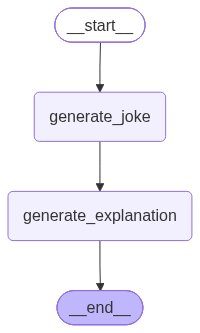

In [14]:
# draw workflow graph
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())